In [1]:
import pandas as pd
import joblib
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load test data
X_test = pd.read_csv("../data/X_test_processed.csv")
y_test = pd.read_csv("../data/y_test_processed.csv").squeeze()

# Load trained models
logistic_model = joblib.load("../data/logistic_regression_model.pkl")
decision_tree_model = joblib.load("../data/decision_tree_model.pkl")
random_forest_model = joblib.load("../data/random_forest_model.pkl")

print("Test data loaded:", X_test.shape)
print("Models loaded successfully!")

Test data loaded: (1409, 32)
Models loaded successfully!


In [2]:
# Logistic Regression predictions
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)
logistic_recall = recall_score(y_test, logistic_predictions)
logistic_f1 = f1_score(y_test, logistic_predictions)
logistic_roc_auc = roc_auc_score(y_test, logistic_probabilities)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1 Score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.85805535841022
Precision: 0.7589285714285714
Recall   : 0.6818181818181818
F1 Score : 0.7183098591549296
ROC-AUC  : 0.9275878994549072


In [3]:
# Decision Tree predictions
decision_tree_predictions = decision_tree_model.predict(X_test)
decision_tree_probabilities = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
decision_tree_accuracy = accuracy_score(y_test, decision_tree_predictions)
decision_tree_precision = precision_score(y_test, decision_tree_predictions)
decision_tree_recall = recall_score(y_test, decision_tree_predictions)
decision_tree_f1 = f1_score(y_test, decision_tree_predictions)
decision_tree_roc_auc = roc_auc_score(y_test, decision_tree_probabilities)

print("Decision Tree Results")
print("--------------------")
print("Accuracy :", decision_tree_accuracy)
print("Precision:", decision_tree_precision)
print("Recall   :", decision_tree_recall)
print("F1 Score :", decision_tree_f1)
print("ROC-AUC  :", decision_tree_roc_auc)

Decision Tree Results
--------------------
Accuracy : 0.8537970191625266
Precision: 0.7245989304812834
Recall   : 0.7245989304812834
F1 Score : 0.7245989304812834
ROC-AUC  : 0.9116045364127205


In [4]:
# Random Forest predictions
random_forest_predictions = random_forest_model.predict(X_test)
random_forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
random_forest_accuracy = accuracy_score(y_test, random_forest_predictions)
random_forest_precision = precision_score(y_test, random_forest_predictions)
random_forest_recall = recall_score(y_test, random_forest_predictions)
random_forest_f1 = f1_score(y_test, random_forest_predictions)
random_forest_roc_auc = roc_auc_score(y_test, random_forest_probabilities)

print("Random Forest Results")
print("--------------------")
print("Accuracy :", random_forest_accuracy)
print("Precision:", random_forest_precision)
print("Recall   :", random_forest_recall)
print("F1 Score :", random_forest_f1)
print("ROC-AUC  :", random_forest_roc_auc)

Random Forest Results
--------------------
Accuracy : 0.8594748048261178
Precision: 0.7619047619047619
Recall   : 0.6844919786096256
F1 Score : 0.7211267605633803
ROC-AUC  : 0.9258854529954275


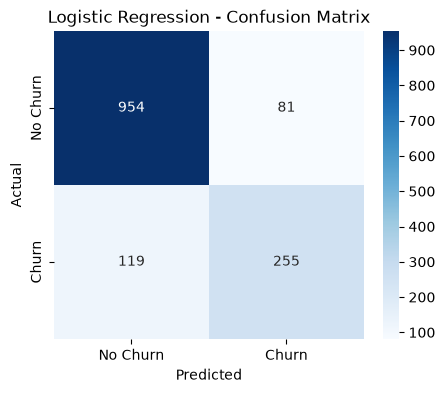

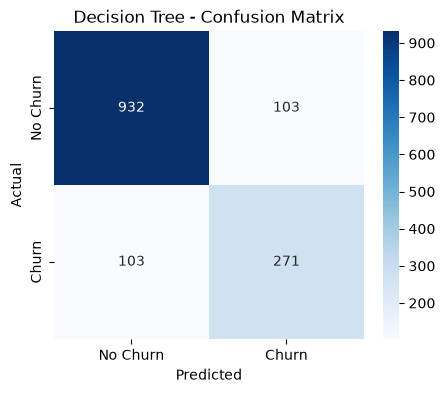

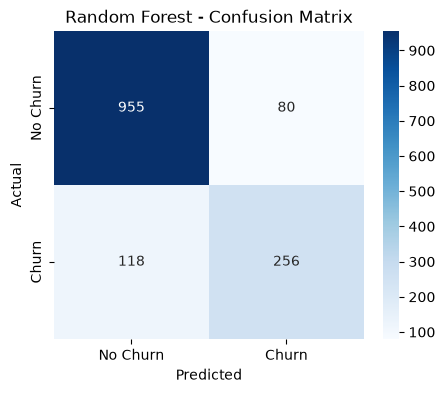

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrices
logistic_cm = confusion_matrix(y_test, logistic_predictions)
decision_tree_cm = confusion_matrix(y_test, decision_tree_predictions)
random_forest_cm = confusion_matrix(y_test, random_forest_predictions)

# Logistic Regression
plt.figure(figsize=(5, 4))
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Decision Tree
plt.figure(figsize=(5, 4))
sns.heatmap(
    decision_tree_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Random Forest
plt.figure(figsize=(5, 4))
sns.heatmap(
    random_forest_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

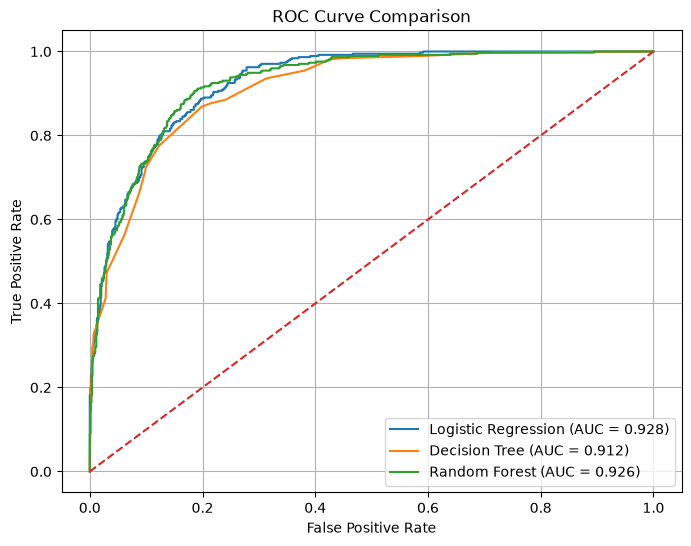

In [6]:
from sklearn.metrics import roc_curve

# Calculate ROC curve values
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test, logistic_probabilities
)

decision_tree_fpr, decision_tree_tpr, _ = roc_curve(
    y_test, decision_tree_probabilities
)

random_forest_fpr, random_forest_tpr, _ = roc_curve(
    y_test, random_forest_probabilities
)

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_roc_auc:.3f})"
)

plt.plot(
    decision_tree_fpr,
    decision_tree_tpr,
    label=f"Decision Tree (AUC = {decision_tree_roc_auc:.3f})"
)

plt.plot(
    random_forest_fpr,
    random_forest_tpr,
    label=f"Random Forest (AUC = {random_forest_roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid()
plt.show()